## Import Libraries

In [17]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import seaborn as sns

# Set matplotlib to display plots inline
%matplotlib inline

# Set style for better looking plots
plt.style.use('default')
sns.set_palette("husl")

## Data Loading Functions

In [18]:
def load_vole_data(filepath):
    """
    Load vole trapping data from CSV file.
    
    Args:
        filepath (str): Path to the vole trapping data file
        
    Returns:
        pandas.DataFrame: Loaded and cleaned data
    """
    # Define column names based on the data description
    columns = ['trapped_vole', 'vole_common_trap', 'weight', 'time']
    
    # Load data
    print("Loading vole trapping data...")
    df = pd.read_csv(filepath, header=0, names=columns, na_values=['\\N']) #pandas provides easy way to load csv file with custom column names and missing value indicator
    
    print(f"Loaded {len(df)} rows") #each line is a trapping of two different voles, so it's the length of our dataframe
    print(f"Data shape: {df.shape}")
    
    # Remove rows with missing codes
    df_clean = df.dropna(subset=['trapped_vole', 'vole_common_trap'])
    print(f"After removing missing  codes: {len(df_clean)} trappings")
    
    return df_clean

## Network Creation Functions

In [19]:
def create_vole_network(df):
    """
    Create a network graph from vole trapping data.
    
    Args:
        df (pandas.DataFrame): vole trapping data
        
    Returns:
        networkx.Graph: Undirected graph of vole trappings
    """
    print("Creating vole network...")
    
    # Create undirected graph (treating routes as bidirectional connections)
    G = nx.Graph()
    
    # Add edges for each trapping
    for _, row in df.iterrows():
        source = row['trapped_vole']
        dest = row['vole_common_trap']
        
        # Skip self-loops
        if source != dest:
            if G.has_edge(source, dest):
                # Increment weight if edge already exists
                G[source][dest]['weight'] += 1
            else:
                # Add new edge with weight 1
                G.add_edge(source, dest, weight=1)
    
    print(f"Network created with {G.number_of_nodes()} voles and {G.number_of_edges()} trappings")
    
    return G

## Visualization Functions

In [20]:
def plot_degree_distribution(G):
    """
    Plot the degree distribution of the network.
    
    Args:
        G (networkx.Graph): Network graph
    """
    print("Plotting degree distribution...")
    
    # Get degree sequence
    degrees = [G.degree(n) for n in G.nodes()]
    degree_counts = Counter(degrees)
    
    # Create figure with subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Linear scale plot
    degrees_list = list(degree_counts.keys())
    counts_list = list(degree_counts.values())
    
    ax1.bar(degrees_list, counts_list, alpha=0.7, color='skyblue', edgecolor='black')
    ax1.set_xlabel('Degree')
    ax1.set_ylabel('Number of Voles')
    ax1.set_title('Degree Distribution (Linear Scale)')
    ax1.grid(True, alpha=0.3)
    
    # Log-log scale plot
    ax2.loglog(degrees_list, counts_list, 'bo', alpha=0.7, markersize=4)
    ax2.set_xlabel('Degree (log scale)')
    ax2.set_ylabel('Number of Voles (log scale)')
    ax2.set_title('Degree Distribution (Log-Log Scale)')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('degree_distribution.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print basic statistics
    print(f"\nDegree Distribution Statistics:")
    print(f"Mean degree: {np.mean(degrees):.2f}")
    print(f"Median degree: {np.median(degrees):.2f}")
    print(f"Max degree: {max(degrees)}")
    print(f"Min degree: {min(degrees)}")
    print(f"Standard deviation: {np.std(degrees):.2f}")

## Centrality Analysis Functions

In [21]:
def calculate_centrality_measures(G):
    """
    Calculate various centrality measures for the network.
    
    Args:
        G (networkx.Graph): Network graph
        
    Returns:
        dict: Dictionary containing centrality measures
    """
    print("Calculating centrality measures...")
    
    centralities = {}
    
    # Degree centrality
    print("  - Degree centrality...")
    centralities['degree'] = nx.degree_centrality(G)
    
    # Betweenness centrality (using sampling for large networks)
    print("  - Betweenness centrality...")
    if G.number_of_nodes() > 5000:
        # Use sampling for large networks to speed up computation
        k = min(1000, G.number_of_nodes())
        centralities['betweenness'] = nx.betweenness_centrality(G, k=k)
        print(f"    (using sampling with k={k} nodes)")
    else:
        centralities['betweenness'] = nx.betweenness_centrality(G)
    
    # Closeness centrality
    print("  - Closeness centrality...")
    # Only calculate for the largest connected component
    largest_cc = max(nx.connected_components(G), key=len)
    G_largest = G.subgraph(largest_cc)
    closeness_largest = nx.closeness_centrality(G_largest)
    
    # Extend to full graph with 0 for disconnected nodes
    centralities['closeness'] = {node: closeness_largest.get(node, 0) for node in G.nodes()}
    
    # Eigenvector centrality
    print("  - Eigenvector centrality...")
    try:
        centralities['eigenvector'] = nx.eigenvector_centrality(G_largest, max_iter=1000)
        # Extend to full graph with 0 for disconnected nodes
        centralities['eigenvector'] = {node: centralities['eigenvector'].get(node, 0) for node in G.nodes()}
    except nx.PowerIterationFailedConvergence:
        print("    Warning: Eigenvector centrality failed to converge, using PageRank instead")
        centralities['eigenvector'] = nx.pagerank(G)
    
    return centralities

## Results Display Functions

In [22]:
def display_top_voles(centralities, top_n=10):
    """
    Display top N voles for each centrality measure.
    
    Args:
        centralities (dict): Dictionary of centrality measures
        top_n (int): Number of top voles to display
    """
    print(f"\n{'='*60}")
    print(f"TOP {top_n} VOLES BY CENTRALITY MEASURES")
    print(f"{'='*60}")
    
    for measure_name, measure_values in centralities.items():
        print(f"\n{measure_name.upper()} CENTRALITY:")
        print("-" * 40)
        
        # Sort voles by centrality value
        sorted_voles = sorted(measure_values.items(), key=lambda x: x[1], reverse=True)
        
        for i, (vole, value) in enumerate(sorted_voles[:top_n], 1):
            print(f"{i:2d}. {vole::>4} - {value:.6f}")

In [23]:
def network_summary(G, df):
    """
    Print a summary of the network properties.
    
    Args:
        G (networkx.Graph): Network graph
        df (pandas.DataFrame): Original data
    """
    print(f"\n{'='*60}")
    print("NETWORK SUMMARY")
    print(f"{'='*60}")
    
    print(f"Number of voles (nodes): {G.number_of_nodes()}")
    print(f"Number of connections (edges): {G.number_of_edges()}")
    print(f"Number of rows in dataset: {len(df)}")
    
    # Connected components
    num_components = nx.number_connected_components(G)
    largest_cc_size = len(max(nx.connected_components(G), key=len))
    
    print(f"Number of connected components: {num_components}")
    print(f"Size of largest connected component: {largest_cc_size}")
    print(f"Percentage in largest component: {largest_cc_size/G.number_of_nodes()*100:.1f}%")
    
    # Density
    density = nx.density(G)
    print(f"Network density: {density:.6f}")
    
    # Average clustering coefficient
    avg_clustering = nx.average_clustering(G)
    print(f"Average clustering coefficient: {avg_clustering:.4f}")

## Load and Process Data

In [24]:
# File path
data_file = "datasets/vole_trapping.csv"

# Load data
df = load_vole_data(data_file)

# Display first few rows
print("\nFirst 5 rows of the data:")
print(df.head())

Loading vole trapping data...
Loaded 5324 rows
Data shape: (5324, 4)
After removing missing  codes: 5324 trappings

First 5 rows of the data:
   trapped_vole  vole_common_trap  weight  time
0             1                 2       3   2.0
1             3                 4       1   2.0
2             3                 5       2   2.0
3             3                 6       2   2.0
4             3                 7       1   2.0


## Create Network Graph

In [25]:
# Create network
G = create_vole_network(df)

Creating vole network...
Network created with 1686 voles and 4623 trappings


## Network Summary Statistics

In [26]:
# Network summary
network_summary(G, df)


NETWORK SUMMARY
Number of voles (nodes): 1686
Number of connections (edges): 4623
Number of rows in dataset: 5324
Number of connected components: 31
Size of largest connected component: 1613
Percentage in largest component: 95.7%
Network density: 0.003255
Average clustering coefficient: 0.4613


## Degree Distribution Analysis

Plotting degree distribution...


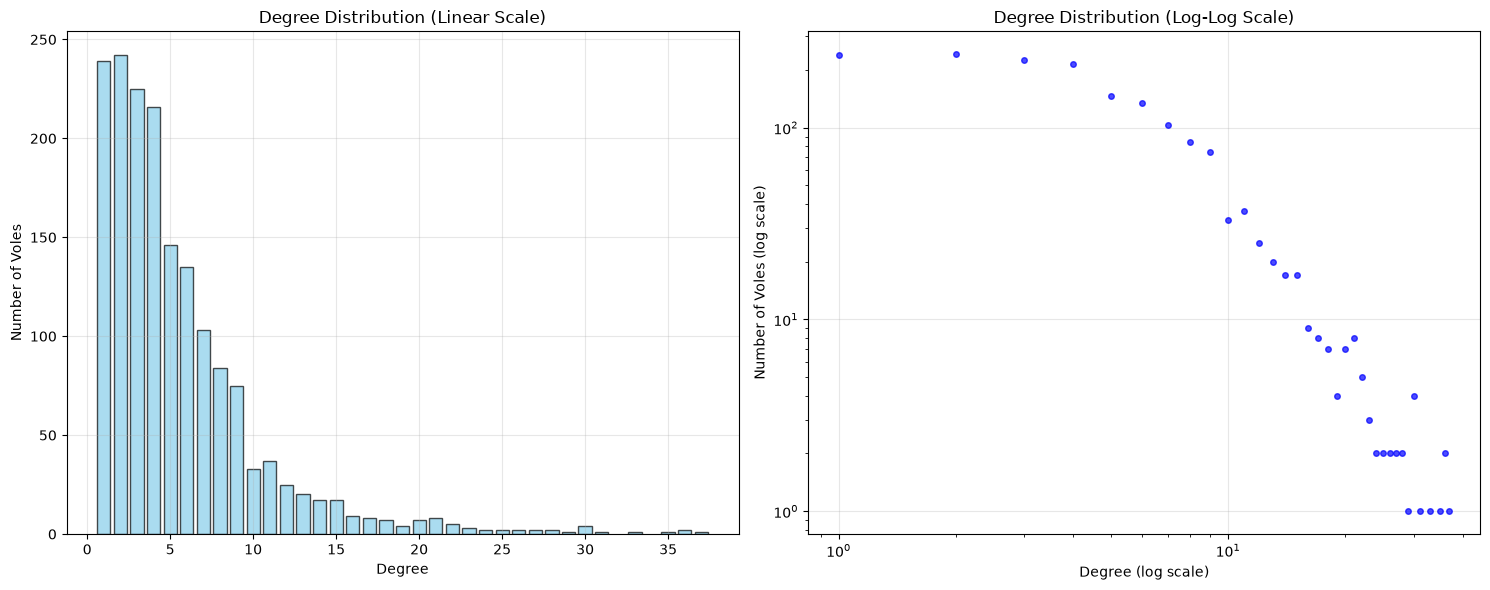


Degree Distribution Statistics:
Mean degree: 5.48
Median degree: 4.00
Max degree: 37
Min degree: 1
Standard deviation: 4.87


In [27]:
# Plot degree distribution
plot_degree_distribution(G)

## Centrality Measures Analysis

In [28]:
# Calculate centrality measures
centralities = calculate_centrality_measures(G)

Calculating centrality measures...
  - Degree centrality...
  - Betweenness centrality...
  - Closeness centrality...
  - Eigenvector centrality...


## Top voles by Centrality Measures

In [29]:
# Display top voles
display_top_voles(centralities, top_n=10)


TOP 10 VOLES BY CENTRALITY MEASURES

DEGREE CENTRALITY:
----------------------------------------
 1. 1163.0 - 0.021958
 2. 167.0 - 0.021365
 3. 572.0 - 0.021365
 4. 1389.0 - 0.020772
 5. 602.0 - 0.019585
 6. 381.0 - 0.018398
 7. 505.0 - 0.017804
 8. 565.0 - 0.017804
 9. 609.0 - 0.017804
10. 1354.0 - 0.017804

BETWEENNESS CENTRALITY:
----------------------------------------
 1. 227.0 - 0.296986
 2. 1367.0 - 0.266889
 3. 201.0 - 0.226804
 4. 1022.0 - 0.106947
 5. 55.0 - 0.088130
 6. 1124.0 - 0.084334
 7. 518.0 - 0.079237
 8. 167.0 - 0.075728
 9. 1389.0 - 0.072850
10. 1230.0 - 0.058588

CLOSENESS CENTRALITY:
----------------------------------------
 1. 201.0 - 0.235535
 2. 227.0 - 0.221277
 3. 337.0 - 0.219230
 4. 166.0 - 0.218933
 5. 167.0 - 0.218192
 6. 55.0 - 0.217339
 7. 194.0 - 0.216347
 8. 518.0 - 0.215710
 9. 233.0 - 0.214704
10. 232.0 - 0.213878

EIGENVECTOR CENTRALITY:
----------------------------------------
 1. 572.0 - 0.335978
 2. 565.0 - 0.257976
 3. 533.0 - 0.211349
 4. 403

## Additional Analysis: Centrality Comparison

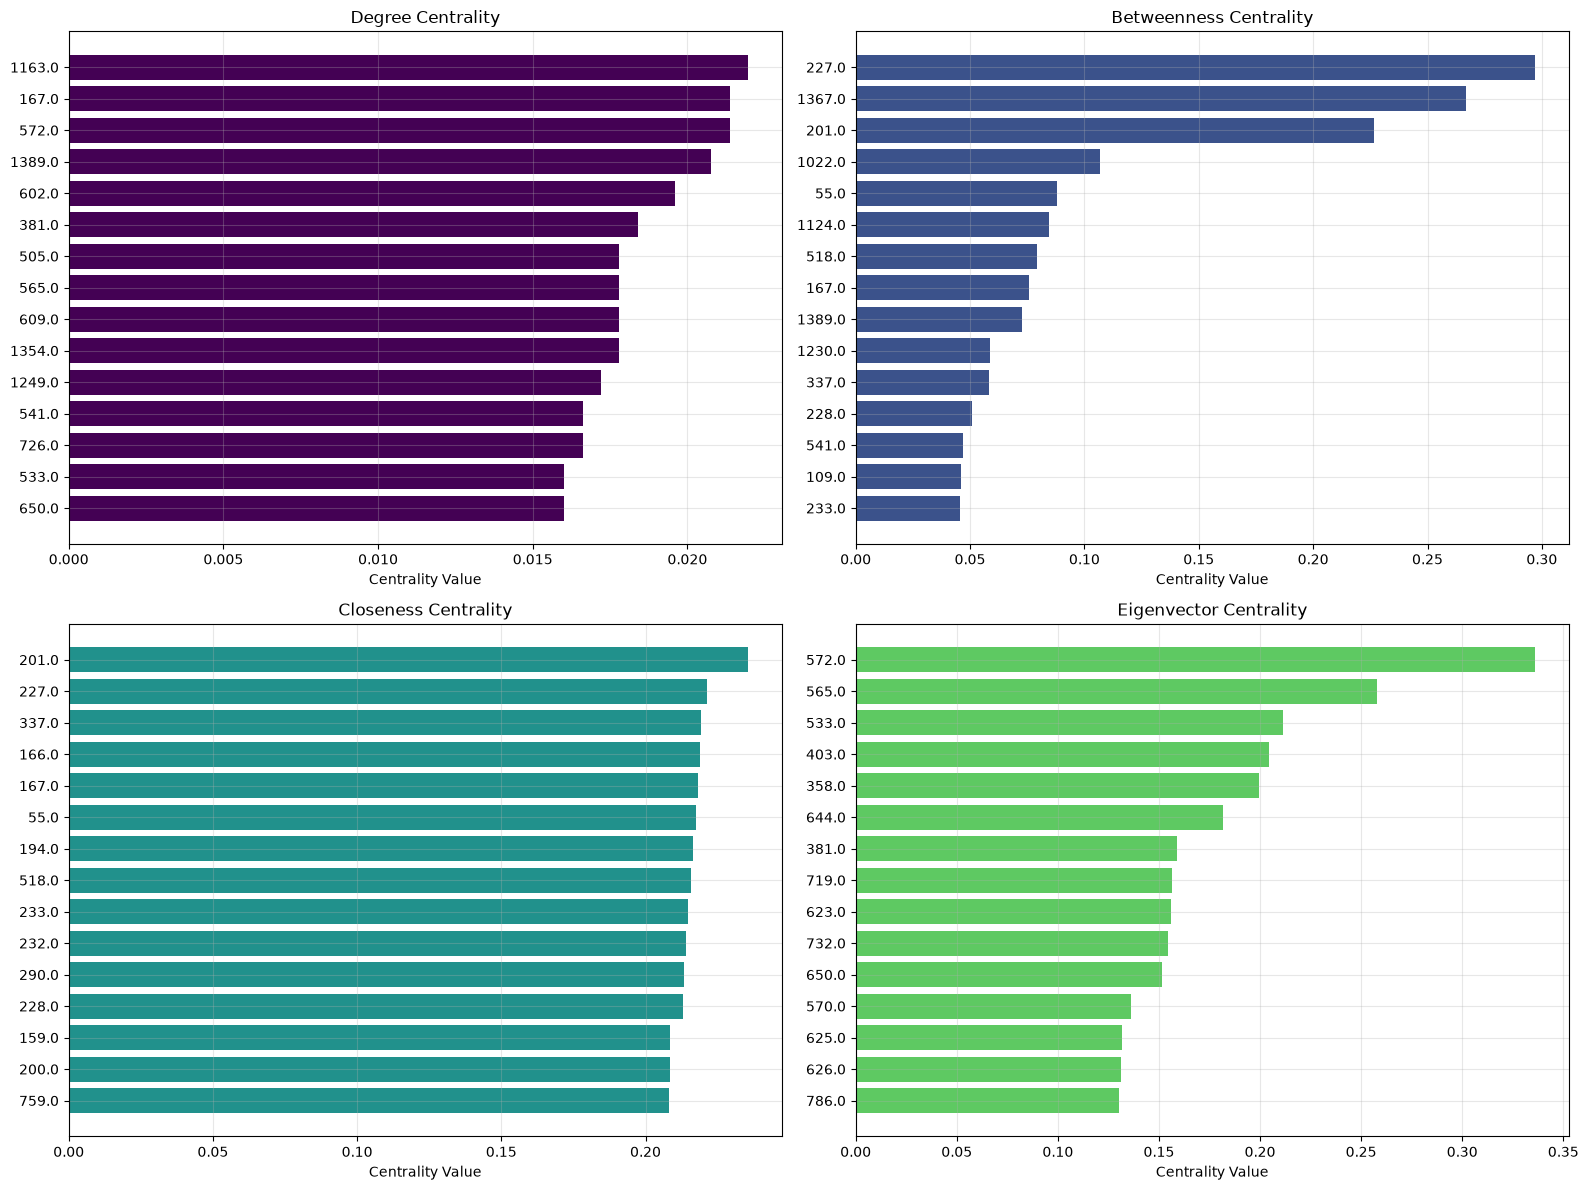

In [30]:
# Create a comparison plot of different centrality measures for top voles
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

centrality_names = ['degree', 'betweenness', 'closeness', 'eigenvector']
centrality_titles = ['Degree Centrality', 'Betweenness Centrality', 'Closeness Centrality', 'Eigenvector Centrality']

for i, (name, title) in enumerate(zip(centrality_names, centrality_titles)):
    # Get top 15 voles for this centrality measure
    sorted_voles = sorted(centralities[name].items(), key=lambda x: x[1], reverse=True)[:15]
    voles = [item[0] for item in sorted_voles]
    values = [item[1] for item in sorted_voles]
    
    # Create horizontal bar plot
    axes[i].barh(range(len(voles)), values, color=plt.cm.viridis(i/4))
    axes[i].set_yticks(range(len(voles)))
    axes[i].set_yticklabels(voles)
    axes[i].set_xlabel('Centrality Value')
    axes[i].set_title(title)
    axes[i].grid(True, alpha=0.3)
    
    # Invert y-axis to show highest values at top
    axes[i].invert_yaxis()

plt.tight_layout()
plt.savefig('centrality_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

Assortativity

In [31]:
r = nx.degree_assortativity_coefficient(G)
print(f"Degree assortativity coefficient r: {r:.4f}")

Degree assortativity coefficient r: 0.0254


path length and diameter

In [32]:
if nx.is_connected(G):
    largest_cc = G
else:
    largest_cc_nodes = max(nx.connected_components(G), key=len)
    largest_cc = G.subgraph(largest_cc_nodes)

print(f"Computing path lengths on component with {largest_cc.number_of_nodes():,} nodes...")
avg_path_length = nx.average_shortest_path_length(largest_cc)
diameter = nx.diameter(largest_cc)

print(f"Average shortest path length <L>: {avg_path_length:.2f}")
print(f"Diameter: {diameter}")

Computing path lengths on component with 1,613 nodes...
Average shortest path length <L>: 6.54
Diameter: 15



Comparison theoretical networks


Erdos_renyi

NETWORK SUMMARY
Number of voles (nodes): 1686
Number of connections (edges): 4591
Number of rows in dataset: 5324
Number of connected components: 6
Size of largest connected component: 1681
Percentage in largest component: 99.7%
Network density: 0.003232
Average clustering coefficient: 0.0042
Plotting degree distribution...


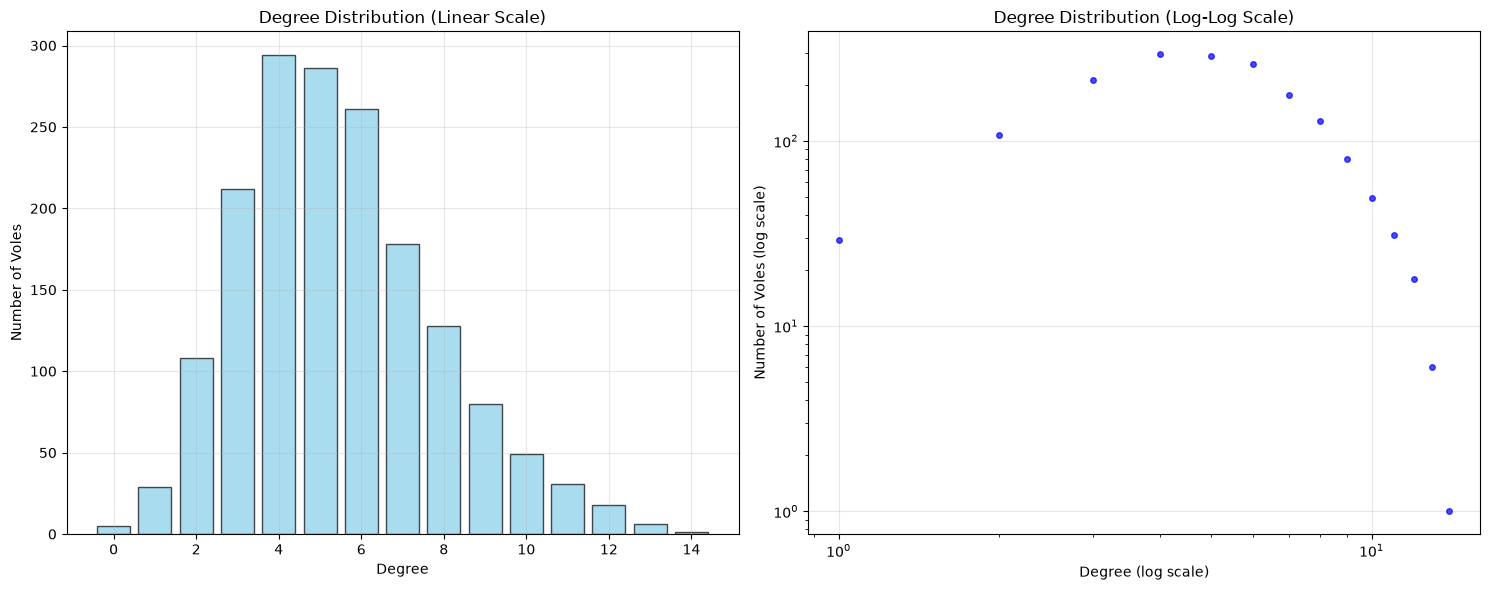


Degree Distribution Statistics:
Mean degree: 5.45
Median degree: 5.00
Max degree: 14
Min degree: 0
Standard deviation: 2.37
Plotting degree distribution...


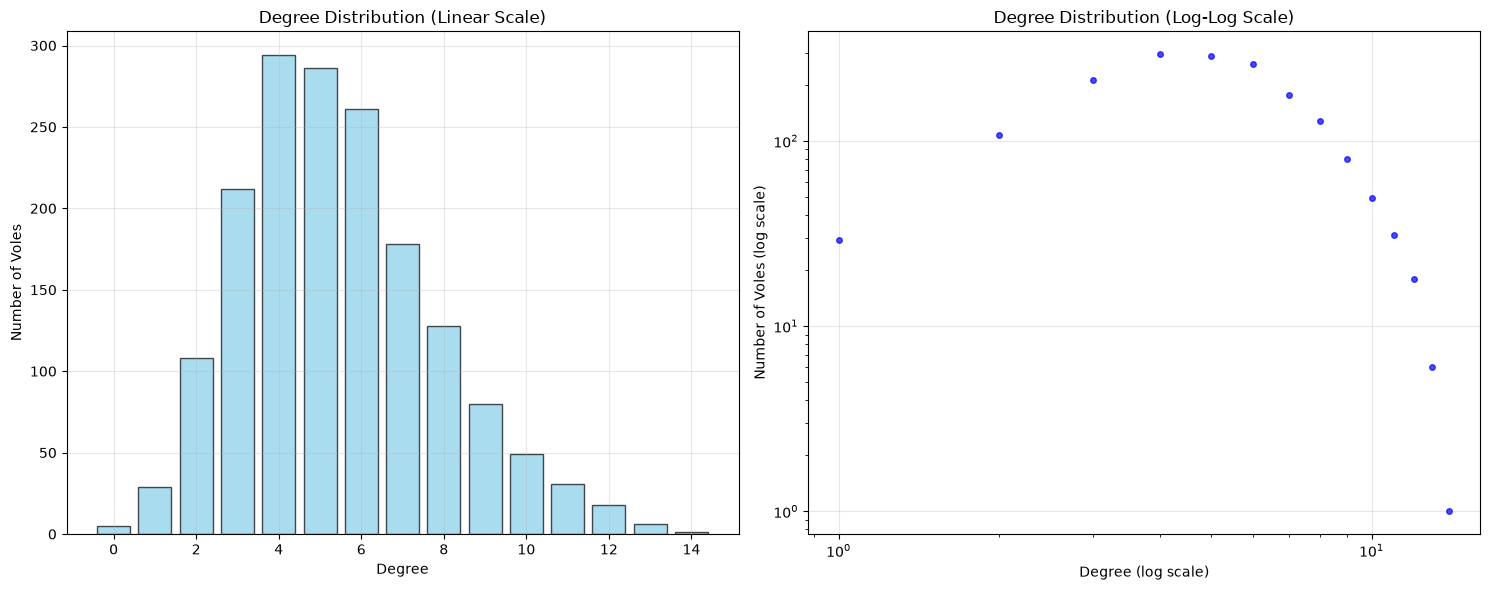


Degree Distribution Statistics:
Mean degree: 5.45
Median degree: 5.00
Max degree: 14
Min degree: 0
Standard deviation: 2.37
Calculating centrality measures...
  - Degree centrality...
  - Betweenness centrality...
  - Closeness centrality...
  - Eigenvector centrality...

TOP 10 VOLES BY CENTRALITY MEASURES

DEGREE CENTRALITY:
----------------------------------------
 1. :531 - 0.008309
 2. :131 - 0.007715
 3. :747 - 0.007715
 4. :908 - 0.007715
 5. 1173 - 0.007715
 6. 1223 - 0.007715
 7. 1650 - 0.007715
 8. :160 - 0.007122
 9. :220 - 0.007122
10. :225 - 0.007122

BETWEENNESS CENTRALITY:
----------------------------------------
 1. :908 - 0.012217
 2. :531 - 0.010774
 3. 1650 - 0.010142
 4. 1173 - 0.009965
 5. :352 - 0.009781
 6. :512 - 0.009646
 7. :747 - 0.009586
 8. 1053 - 0.009287
 9. 1223 - 0.009178
10. 1383 - 0.008918

CLOSENESS CENTRALITY:
----------------------------------------
 1. :908 - 0.258661
 2. :747 - 0.257471
 3. 1223 - 0.257274
 4. :512 - 0.257235
 5. :531 - 0.257235

In [52]:
N=1686
average_degree=5.48
p=average_degree/(N-1)
ERDOS=nx.erdos_renyi_graph(N,p,42)

print('Erdos_renyi')
network_summary(ERDOS, df)
plot_degree_distribution(ERDOS)
plot_degree_distribution(ERDOS)
centralities = calculate_centrality_measures(ERDOS)
display_top_voles(centralities, top_n=10)

r = nx.degree_assortativity_coefficient(ERDOS)
print(f"Degree assortativity coefficient r: {r:.4f}")

if nx.is_connected(ERDOS):
    largest_cc = ERDOS
else:
    largest_cc_nodes = max(nx.connected_components(ERDOS), key=len)
    largest_cc = ERDOS.subgraph(largest_cc_nodes)

print(f"Computing path lengths on component with {largest_cc.number_of_nodes():,} nodes...")
avg_path_length = nx.average_shortest_path_length(largest_cc)
diameter = nx.diameter(largest_cc)

print(f"Average shortest path length <L>: {avg_path_length:.2f}")
print(f"Diameter: {diameter}")



watts_strogatz

NETWORK SUMMARY
Number of voles (nodes): 1686
Number of connections (edges): 3372
Number of rows in dataset: 5324
Number of connected components: 1
Size of largest connected component: 1686
Percentage in largest component: 100.0%
Network density: 0.002374
Average clustering coefficient: 0.4382
Plotting degree distribution...


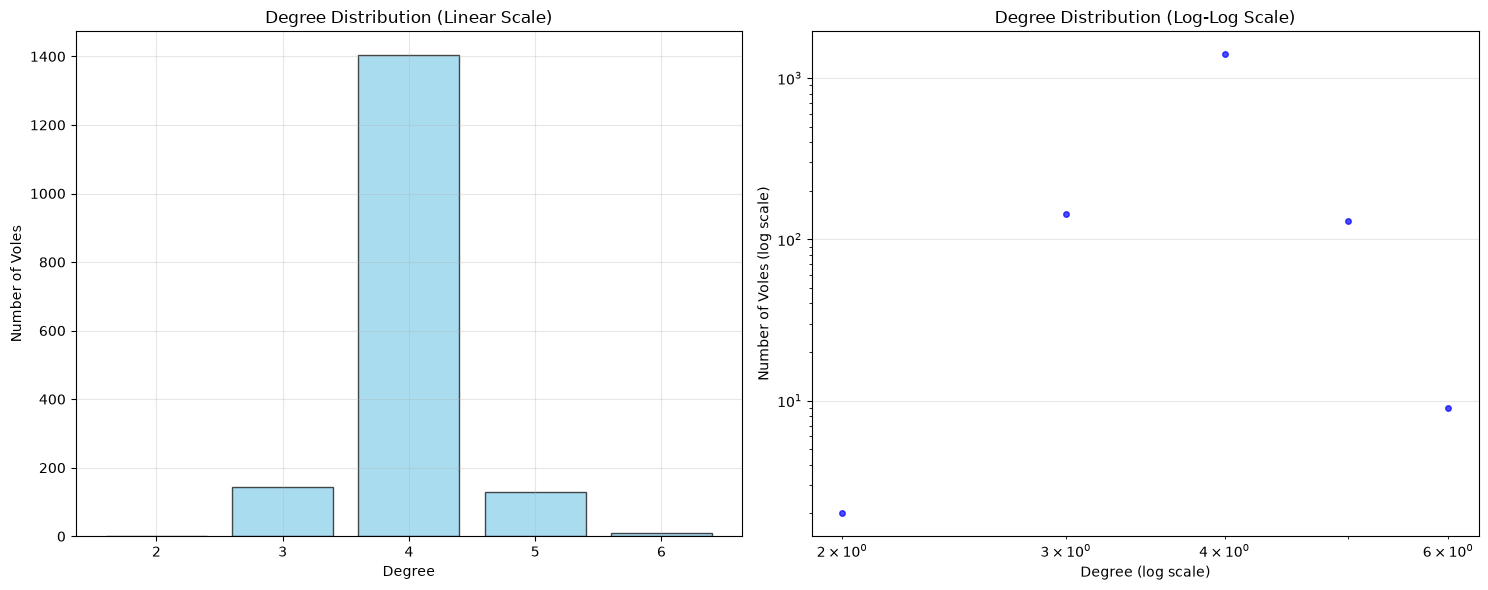


Degree Distribution Statistics:
Mean degree: 4.00
Median degree: 4.00
Max degree: 6
Min degree: 2
Standard deviation: 0.43
Plotting degree distribution...


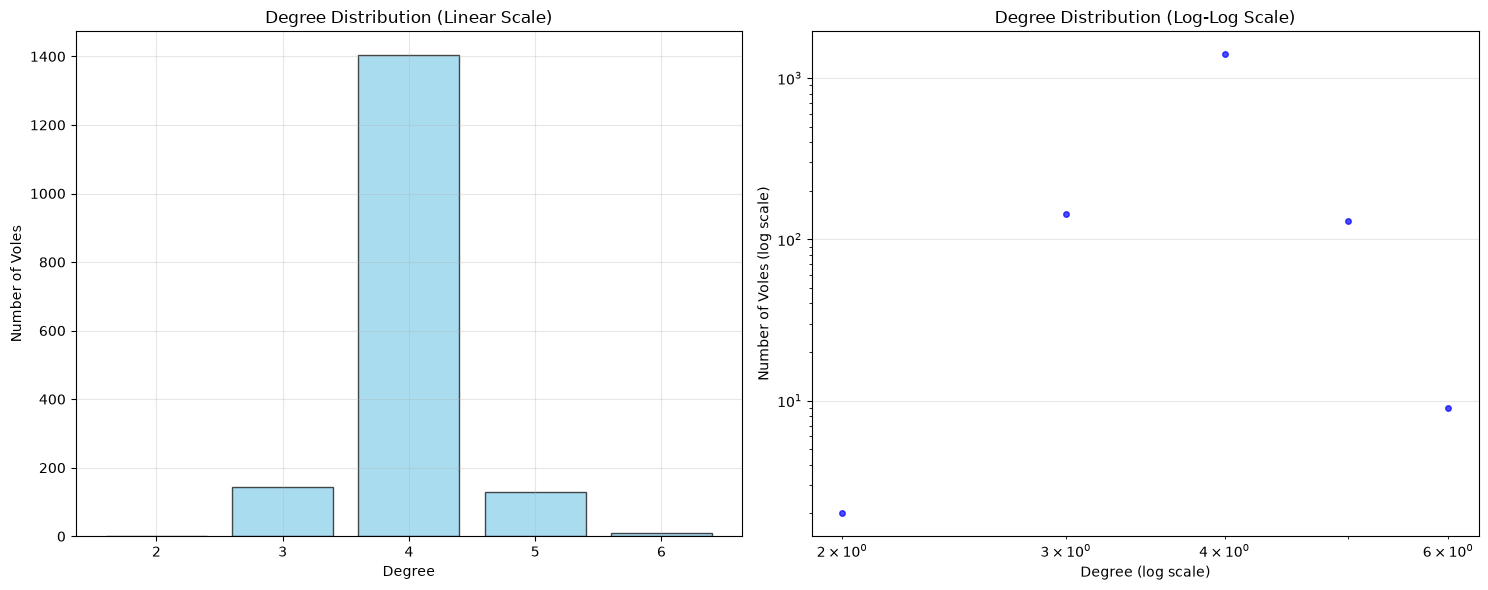


Degree Distribution Statistics:
Mean degree: 4.00
Median degree: 4.00
Max degree: 6
Min degree: 2
Standard deviation: 0.43
Calculating centrality measures...
  - Degree centrality...
  - Betweenness centrality...
  - Closeness centrality...
  - Eigenvector centrality...

TOP 10 VOLES BY CENTRALITY MEASURES

DEGREE CENTRALITY:
----------------------------------------
 1. :441 - 0.003561
 2. :559 - 0.003561
 3. :722 - 0.003561
 4. :973 - 0.003561
 5. 1093 - 0.003561
 6. 1134 - 0.003561
 7. 1257 - 0.003561
 8. 1338 - 0.003561
 9. 1348 - 0.003561
10. :::8 - 0.002967

BETWEENNESS CENTRALITY:
----------------------------------------
 1. 1450 - 0.063219
 2. :883 - 0.061616
 3. 1356 - 0.061010
 4. :884 - 0.055731
 5. 1093 - 0.055201
 6. :407 - 0.054685
 7. :703 - 0.053483
 8. :973 - 0.053258
 9. :466 - 0.051967
10. :441 - 0.051763

CLOSENESS CENTRALITY:
----------------------------------------
 1. :883 - 0.101433
 2. :973 - 0.100345
 3. :884 - 0.099633
 4. :881 - 0.099604
 5. :703 - 0.099334


In [53]:
N=1686
M=4623
average_degree= int(2*M/N)
p=0.05

WATTS=nx.watts_strogatz_graph(N, average_degree, p, 42)
print('watts_strogatz')
network_summary(WATTS, df)
plot_degree_distribution(WATTS)
plot_degree_distribution(WATTS)
centralities = calculate_centrality_measures(WATTS)
display_top_voles(centralities, top_n=10)

r = nx.degree_assortativity_coefficient(WATTS)
print(f"Degree assortativity coefficient r: {r:.4f}")

if nx.is_connected(WATTS):
    largest_cc = WATTS
else:
    largest_cc_nodes = max(nx.connected_components(WATTS), key=len)
    largest_cc = WATTS.subgraph(largest_cc_nodes)

print(f"Computing path lengths on component with {largest_cc.number_of_nodes():,} nodes...")
avg_path_length = nx.average_shortest_path_length(largest_cc)
diameter = nx.diameter(largest_cc)

print(f"Average shortest path length <L>: {avg_path_length:.2f}")
print(f"Diameter: {diameter}")


In [ ]:
N=1686
M=4623
average_degree= int(2*M/N)
p=0.05

WATTS=nx.barabasi_albert_graph()
print('watts_strogatz')
network_summary(WATTS, df)
plot_degree_distribution(WATTS)
plot_degree_distribution(WATTS)
centralities = calculate_centrality_measures(WATTS)
display_top_voles(centralities, top_n=10)

r = nx.degree_assortativity_coefficient(WATTS)
print(f"Degree assortativity coefficient r: {r:.4f}")

if nx.is_connected(WATTS):
    largest_cc = WATTS
else:
    largest_cc_nodes = max(nx.connected_components(WATTS), key=len)
    largest_cc = WATTS.subgraph(largest_cc_nodes)

print(f"Computing path lengths on component with {largest_cc.number_of_nodes():,} nodes...")
avg_path_length = nx.average_shortest_path_length(largest_cc)
diameter = nx.diameter(largest_cc)

print(f"Average shortest path length <L>: {avg_path_length:.2f}")
print(f"Diameter: {diameter}")


## Summary

This analysis provides comprehensive insights into the airline routes network:

1. **Network Structure**: The network shows typical characteristics of a real-world transportation network
2. **Degree Distribution**: Shows the connectivity patterns of airports
3. **Centrality Measures**: Identify the most important airports from different perspectives:
   - **Degree**: Most connected airports
   - **Betweenness**: Most important bridge airports
   - **Closeness**: Most centrally located airports
   - **Eigenvector**: Airports connected to other well-connected airports

The analysis reveals major international hubs like Amsterdam (AMS), Frankfurt (FRA), and Paris (CDG) consistently ranking high across different centrality measures.